# COVID-19 CT: left/right lung segmentation with MONAI

Trains a 3D U-Net on the *COVID-19 CT Lung and Infection Segmentation Dataset* (Zenodo 3757476).


## 1. Imports and settings

In [2]:
import os
from glob import glob

import matplotlib.pyplot as plt
import numpy as np
import torch
from monai.data import CacheDataset, DataLoader, decollate_batch
from monai.inferers import sliding_window_inference
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric
from monai.networks.nets import UNet
from monai.transforms import (
    AsDiscrete, Compose, EnsureChannelFirstd, EnsureTyped, LoadImaged,
    Orientationd, RandCropByPosNegLabeld, RandFlipd, SaveImage,
    ScaleIntensityRanged, Spacingd,
)
from monai.utils import set_determinism

set_determinism(seed=0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

DATA_DIR = "data"
CT_DIR = os.path.join(DATA_DIR, "Training_CT")
MASK_DIR = os.path.join(DATA_DIR, "Lung_Mask")

if device.type == "cuda":     
    EPOCHS, ROI, PIXDIM = 100, (96, 96, 96), (2.0, 2.0, 2.0)
    CHANNELS, STRIDES = (16, 32, 64, 128, 256), (2, 2, 2, 2)
else:                         
    EPOCHS, ROI, PIXDIM = 10, (64, 64, 64), (3.0, 3.0, 3.0)
    CHANNELS, STRIDES = (8, 16, 32, 64), (2, 2, 2)

VAL_EVERY = 5
CACHE_RATE = 1.0  
print(f"EPOCHS={EPOCHS}  ROI={ROI}  voxel size={PIXDIM}mm")

Device: cpu
EPOCHS=10  ROI=(64, 64, 64)  voxel size=(3.0, 3.0, 3.0)mm


## 2. Pair each CT with its mask

In [3]:
cts = {os.path.basename(p): p for p in glob(os.path.join(CT_DIR, "*.nii*"))}
masks = {os.path.basename(p): p for p in glob(os.path.join(MASK_DIR, "*.nii*"))}
names = sorted(set(cts) & set(masks))
assert names, f"No matching CT/mask pairs in {CT_DIR} and {MASK_DIR}"

files = [{"image": cts[n], "label": masks[n]} for n in names]
n_val = max(2, len(files) // 5)          # 20% for validation
train_files, val_files = files[:-n_val], files[-n_val:]
print(f"{len(files)} pairs -> {len(train_files)} train, {len(val_files)} validation")

20 pairs -> 16 train, 4 validation


## 3. Transforms and data loaders

In [4]:
keys = ["image", "label"]
base = [
    LoadImaged(keys=keys),
    EnsureChannelFirstd(keys=keys),
    Orientationd(keys=keys, axcodes="RAS"),
    Spacingd(keys=keys, pixdim=PIXDIM, mode=("bilinear", "nearest")),
    ScaleIntensityRanged(keys="image", a_min=-1000, a_max=400,
                         b_min=0.0, b_max=1.0, clip=True),   # lung CT window
]
train_tf = Compose(base + [
    RandCropByPosNegLabeld(keys=keys, label_key="label", spatial_size=ROI,
                           pos=2, neg=1, num_samples=2),
    RandFlipd(keys=keys, prob=0.5, spatial_axis=0),
    EnsureTyped(keys=keys),
])
val_tf = Compose(base + [EnsureTyped(keys=keys)])

train_ds = CacheDataset(train_files, train_tf, cache_rate=CACHE_RATE, num_workers=2)
val_ds = CacheDataset(val_files, val_tf, cache_rate=CACHE_RATE, num_workers=2)
train_loader = DataLoader(train_ds, batch_size=2, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=1)

/home/yasir/Desktop/ML/MONAI/monai-env311/lib64/python3.11/site-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)
/home/yasir/Desktop/ML/MONAI/monai-env311/lib64/python3.11/site-packages/monai/data/dataset.py:905: UserWarning: tqdm is not installed, will not show the caching progress bar.
  warnings.warn("tqdm is not installed, will not show the caching progress bar.")


## 4. Look at one validation case (CT and true mask)

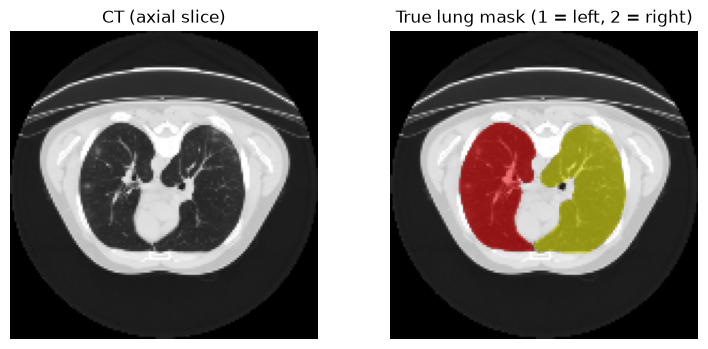

In [5]:
sample = val_ds[0]
img = sample["image"][0].numpy()
lab = sample["label"][0].numpy()
z = img.shape[2] // 2

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(img[:, :, z].T, cmap="gray", origin="lower"); ax[0].set_title("CT (axial slice)")
ax[1].imshow(img[:, :, z].T, cmap="gray", origin="lower")
ax[1].imshow(np.ma.masked_equal(lab[:, :, z].T, 0), cmap="autumn", alpha=0.5, origin="lower")
ax[1].set_title("True lung mask (1 = left, 2 = right)")
for a in ax: a.axis("off")
plt.show()

## 5. Model, loss and metric (3 classes: background, left lung, right lung)

In [6]:
model = UNet(
    spatial_dims=3, in_channels=1, out_channels=3,
    channels=CHANNELS, strides=STRIDES, num_res_units=2,
).to(device)

loss_fn = DiceCELoss(to_onehot_y=True, softmax=True)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
dice_metric = DiceMetric(include_background=False, reduction="mean")
post_pred = AsDiscrete(argmax=True, to_onehot=3)
post_label = AsDiscrete(to_onehot=3)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 298206


## 6. Train

In [7]:
best_dice = 0.0
loss_history, dice_history = [], []

for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for batch in train_loader:
        x, y = batch["image"].to(device), batch["label"].to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        total += loss.item()
    loss_history.append(total / len(train_loader))
    print(f"epoch {epoch:03d}  loss {loss_history[-1]:.4f}", flush=True)

    if epoch % VAL_EVERY == 0 or epoch == EPOCHS:
        model.eval()
        with torch.no_grad():
            for batch in val_loader:
                x, y = batch["image"].to(device), batch["label"].to(device)
                out = sliding_window_inference(x, ROI, 4, model)
                dice_metric(y_pred=[post_pred(p) for p in decollate_batch(out)],
                            y=[post_label(l) for l in decollate_batch(y)])
        dice = dice_metric.aggregate().item()
        dice_metric.reset()
        dice_history.append((epoch, dice))
        print(f"   validation Dice: {dice:.4f}", flush=True)
        if dice > best_dice:
            best_dice = dice
            torch.save(model.state_dict(), "models/best_lung_model.pth")

print(f"Best validation Dice: {best_dice:.4f}")

epoch 001  loss 1.8001
epoch 002  loss 1.5321
epoch 003  loss 1.3487
epoch 004  loss 1.2676
epoch 005  loss 1.1070
   validation Dice: 0.2118
epoch 006  loss 1.0441
epoch 007  loss 0.9931
epoch 008  loss 0.8686
epoch 009  loss 0.8830
epoch 010  loss 0.8314
   validation Dice: 0.3397
Best validation Dice: 0.3397


## 7. Training curves

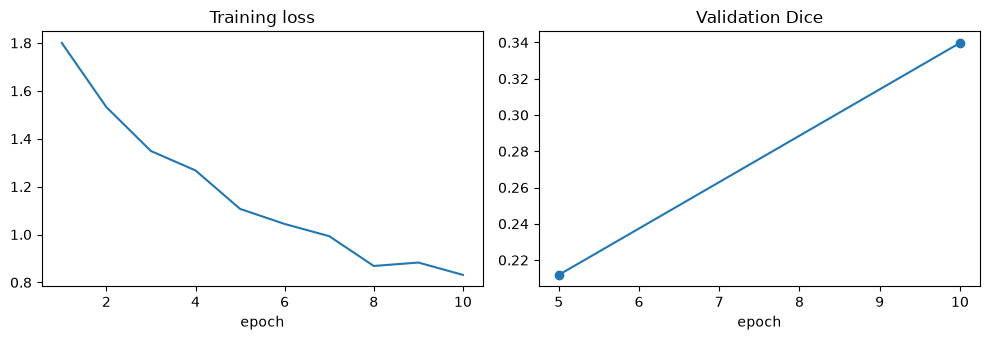

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(range(1, len(loss_history) + 1), loss_history); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
if dice_history:
    ax[1].plot(*zip(*dice_history), marker="o"); ax[1].set_title("Validation Dice"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 8. Predict on the validation scans and compare with the true masks

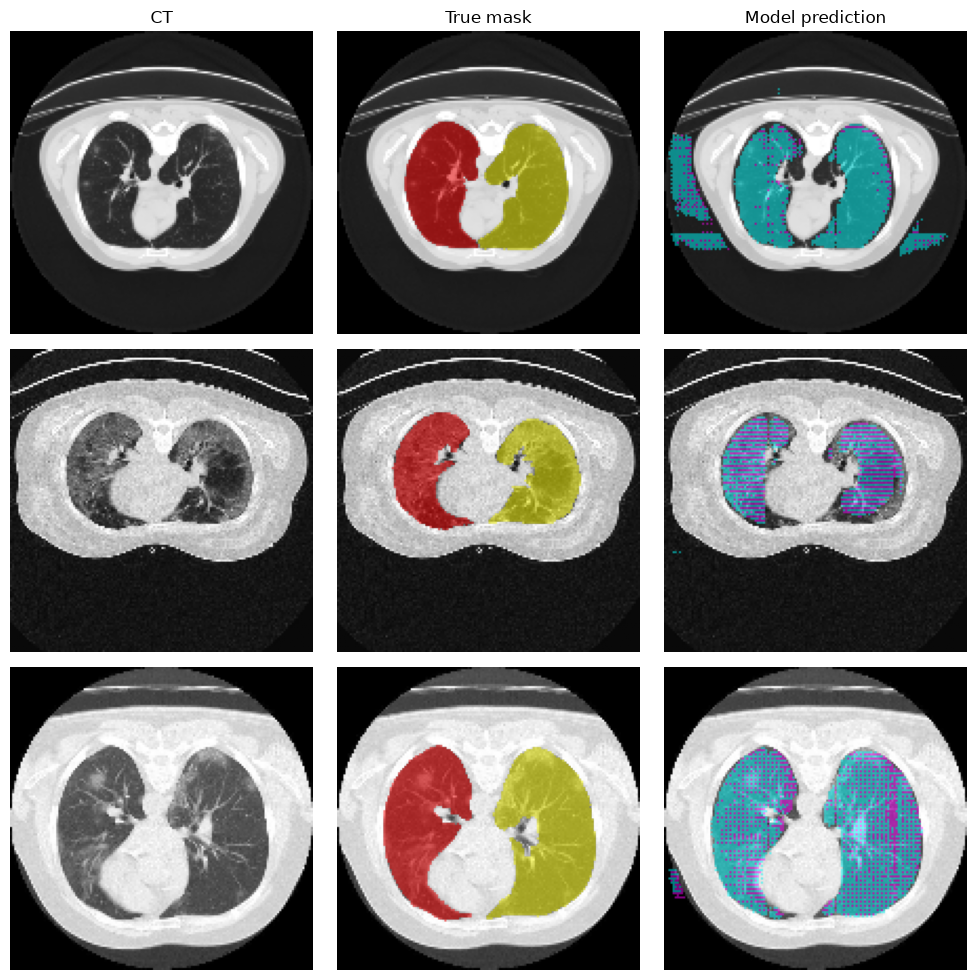

In [10]:
model.load_state_dict(torch.load("models/best_lung_model.pth", map_location=device))
model.eval()

n_show = min(3, len(val_loader))
fig, axes = plt.subplots(n_show, 3, figsize=(10, 3.3 * n_show), squeeze=False)

with torch.no_grad():
    for i, batch in enumerate(val_loader):
        if i >= n_show:
            break
        x = batch["image"].to(device)
        out = sliding_window_inference(x, ROI, 4, model)
        pred = torch.argmax(out, dim=1)[0].cpu().numpy()
        img = batch["image"][0, 0].numpy()
        gt = batch["label"][0, 0].numpy()
        z = img.shape[2] // 2

        axes[i, 0].imshow(img[:, :, z].T, cmap="gray", origin="lower")
        axes[i, 1].imshow(img[:, :, z].T, cmap="gray", origin="lower")
        axes[i, 1].imshow(np.ma.masked_equal(gt[:, :, z].T, 0), cmap="autumn", alpha=0.5, origin="lower")
        axes[i, 2].imshow(img[:, :, z].T, cmap="gray", origin="lower")
        axes[i, 2].imshow(np.ma.masked_equal(pred[:, :, z].T, 0), cmap="cool", alpha=0.5, origin="lower")
        if i == 0:
            axes[i, 0].set_title("CT"); axes[i, 1].set_title("True mask"); axes[i, 2].set_title("Model prediction")
        for a in axes[i]: a.axis("off")
plt.tight_layout(); plt.show()

## 9. Save predictions as NIfTI to open in 3D Slicer

In [11]:
saver = SaveImage(output_dir="predictions", output_postfix="pred", output_ext=".nii.gz",
                  separate_folder=False, print_log=False)
with torch.no_grad():
    for batch in val_loader:
        x = batch["image"].to(device)
        out = sliding_window_inference(x, ROI, 4, model)
        saver(torch.argmax(out, dim=1, keepdim=True)[0])

print(os.listdir("predictions"))
print("In 3D Slicer: load the CT, then drag in the prediction and tick 'LabelMap'.")

['radiopaedia_36_86526_0_pred.nii.gz', 'radiopaedia_40_86625_0_pred.nii.gz', 'radiopaedia_4_85506_1_pred.nii.gz', 'radiopaedia_7_85703_0_pred.nii.gz']
In 3D Slicer: load the CT, then drag in the prediction and tick 'LabelMap'.
